# Improved GCN (Scratch) (Random fold (default))
Early stopping, LR scheduler, dropout, hidden=128, epochs=200.

In [1]:
import pandas as pd
import numpy as np
from rdkit import Chem
import torch
from torch import nn
import helpers as hp

In [2]:
from tdc.single_pred import ADME
data = ADME(name='Lipophilicity_AstraZeneca')
split = data.get_split()

Found local copy...
Loading...
Done!


In [3]:
# Missing values, canonicalization, duplicates
n_rows_before_train = split['train'].shape[0]
n_rows_before_valid = split['valid'].shape[0]
n_rows_before_test = split['test'].shape[0]

split['train']['_source'] = 'train'
split['valid']['_source'] = 'valid'
split['test']['_source'] = 'test'
combined = pd.concat([split['train'], split['valid'], split['test']], ignore_index=True)

combined['Mol'] = combined.Drug.apply(Chem.MolFromSmiles)
combined = combined.dropna(subset=['Mol'])

combined['Canonical_SMILES'] = combined.Mol.apply(lambda x: Chem.MolToSmiles(x, canonical=True))
combined.drop_duplicates(subset='Canonical_SMILES', keep='first', inplace=True)

split['train'] = combined[combined['_source'] == 'train'].drop(columns=['_source'])
split['valid'] = combined[combined['_source'] == 'valid'].drop(columns=['_source'])
split['test'] = combined[combined['_source'] == 'test'].drop(columns=['_source'])

print(f"Training set shape: {split['train'].shape}")
print(f"Validation set shape: {split['valid'].shape}")
print(f"Test set shape: {split['test'].shape}")

Training set shape: (2940, 5)
Validation set shape: (420, 5)
Test set shape: (840, 5)


In [4]:
TARGET_COL = 'Y'
SMILES_COL = 'Canonical_SMILES'
print(f"Target range: [{combined[TARGET_COL].min():.2f}, {combined[TARGET_COL].max():.2f}] log(mol/L)")

Target range: [-1.50, 4.50] log(mol/L)


In [5]:
train_ds = hp.GNNDataset(split['train'][SMILES_COL], split['train'][TARGET_COL])
valid_ds = hp.GNNDataset(split['valid'][SMILES_COL], split['valid'][TARGET_COL])
test_ds = hp.GNNDataset(split['test'][SMILES_COL], split['test'][TARGET_COL])

train_loader = hp.DataLoader(train_ds, batch_size=1, shuffle=True)
val_loader = hp.DataLoader(valid_ds, batch_size=1, shuffle=False)
test_loader = hp.DataLoader(test_ds, batch_size=1, shuffle=False)

print(f'Split — Train: {len(train_ds)}  Val: {len(valid_ds)}  Test: {len(test_ds)}')

Split — Train: 2940  Val: 420  Test: 840


In [6]:
class GCNModelDropout(nn.Module):
    def __init__(self, in_features, hidden, out_features=1, n_layers=2, dropout=0.2, pool_fn=torch.mean):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(hp.GCNLayer(in_features, hidden))
        for _ in range(n_layers - 1):
            self.convs.append(hp.GCNLayer(hidden, hidden))
        self.dropout = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, out_features),
        )
        self.pool_fn = pool_fn

    def forward(self, X, A):
        h = X
        for conv in self.convs:
            h = conv(h, A)
            h = self.dropout(h)
        h_graph = self.pool_fn(h, dim=0)
        return self.readout(h_graph)

In [7]:
torch.manual_seed(0)

gcn = GCNModelDropout(in_features=54, hidden=128, out_features=1, n_layers=2, dropout=0.2)
optimiser = torch.optim.Adam(gcn.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = torch.nn.MSELoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=10)

N_EPOCHS = 200
train_losses, val_losses = [], []

best_val = float('inf')
best_state = None
patience = 20
patience_left = patience

for epoch in range(1, N_EPOCHS + 1):
    gcn.train()
    running = 0.0
    for X_b, A_b, y_b in train_loader:
        X_b, A_b, y_b = X_b.squeeze(0), A_b.squeeze(0), y_b.squeeze(0)
        optimiser.zero_grad()
        pred = gcn(X_b, A_b).squeeze()
        loss = criterion(pred, y_b)
        loss.backward()
        optimiser.step()
        running += loss.item()
    train_rmse = (running / len(train_loader)) ** 0.5
    train_losses.append(train_rmse)

    gcn.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_b, A_b, y_b in val_loader:
            X_b, A_b, y_b = X_b.squeeze(0), A_b.squeeze(0), y_b.squeeze(0)
            pred = gcn(X_b, A_b).squeeze()
            val_loss += criterion(pred, y_b).item()
    val_rmse = (val_loss / len(val_loader)) ** 0.5
    val_losses.append(val_rmse)
    scheduler.step(val_rmse)

    if val_rmse < best_val:
        best_val = val_rmse
        best_state = {k: v.detach().cpu().clone() for k, v in gcn.state_dict().items()}
        patience_left = patience
    else:
        patience_left -= 1

    if epoch % 10 == 0:
        print(f'Epoch {epoch:3d}  Train RMSE: {train_rmse:.4f}  Val RMSE: {val_rmse:.4f}')

    if patience_left == 0:
        print(f'Early stopping at epoch {epoch}')
        break

if best_state is not None:
    gcn.load_state_dict(best_state)

Epoch  10  Train RMSE: 1.0513  Val RMSE: 0.9948
Epoch  20  Train RMSE: 1.0227  Val RMSE: 0.9713
Epoch  30  Train RMSE: 1.0141  Val RMSE: 0.9448
Epoch  40  Train RMSE: 0.9965  Val RMSE: 0.9487
Epoch  50  Train RMSE: 0.9854  Val RMSE: 0.9051
Epoch  60  Train RMSE: 0.9628  Val RMSE: 0.8969
Epoch  70  Train RMSE: 0.9760  Val RMSE: 0.8949
Epoch  80  Train RMSE: 0.9454  Val RMSE: 0.8812
Epoch  90  Train RMSE: 0.9511  Val RMSE: 0.8824
Epoch 100  Train RMSE: 0.9331  Val RMSE: 0.8574
Epoch 110  Train RMSE: 0.9414  Val RMSE: 0.8615
Epoch 120  Train RMSE: 0.9026  Val RMSE: 0.8352
Epoch 130  Train RMSE: 0.9091  Val RMSE: 0.8503
Epoch 140  Train RMSE: 0.8818  Val RMSE: 0.8167
Epoch 150  Train RMSE: 0.8784  Val RMSE: 0.8349
Epoch 160  Train RMSE: 0.8868  Val RMSE: 0.8163
Epoch 170  Train RMSE: 0.8708  Val RMSE: 0.8106
Epoch 180  Train RMSE: 0.8746  Val RMSE: 0.8058
Epoch 190  Train RMSE: 0.8813  Val RMSE: 0.8183
Epoch 200  Train RMSE: 0.8740  Val RMSE: 0.8043


In [8]:
gcn.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for X_b, A_b, y_b in test_loader:
        X_b, A_b, y_b = X_b.squeeze(0), A_b.squeeze(0), y_b.squeeze(0)
        y_true.append(y_b.item())
        y_pred.append(gcn(X_b, A_b).squeeze().item())

y_true, y_pred = np.array(y_true), np.array(y_pred)
rmse_gcn = np.sqrt(np.mean((y_pred - y_true) ** 2))
r2_gcn = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

print(f'Test RMSE: {rmse_gcn:.4f}')
print(f'Test R2: {r2_gcn:.4f}')

Test RMSE: 0.8782
Test R2: 0.4780


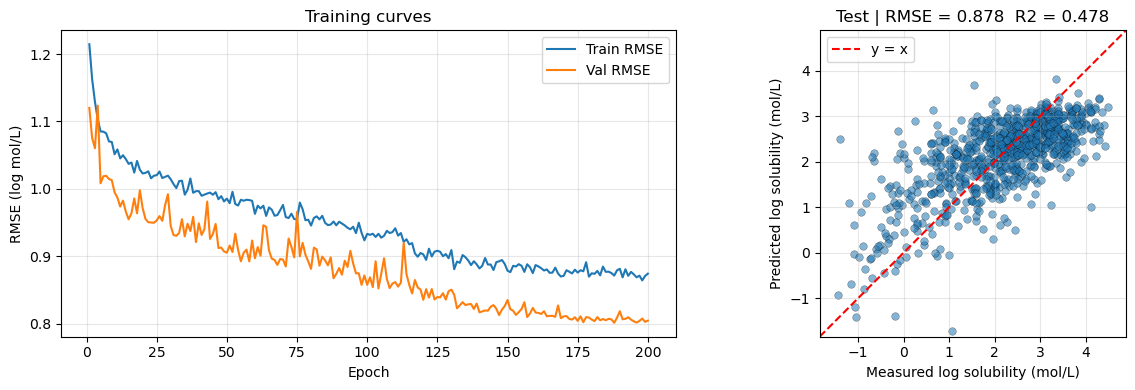

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs = range(1, len(train_losses) + 1)
axes[0].plot(epochs, train_losses, label='Train RMSE')
axes[0].plot(epochs, val_losses, label='Val RMSE')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('RMSE (log mol/L)')
axes[0].set_title('Training curves')
axes[0].legend()
axes[0].grid(alpha=0.3)

lim = [y_true.min() - 0.4, y_true.max() + 0.4]
axes[1].scatter(y_true, y_pred, alpha=0.55, edgecolors='k', linewidth=0.3, s=30)
axes[1].plot(lim, lim, 'r--', linewidth=1.5, label='y = x')
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel('Measured log solubility (mol/L)')
axes[1].set_ylabel('Predicted log solubility (mol/L)')
axes[1].set_title(f'Test | RMSE = {rmse_gcn:.3f}  R2 = {r2_gcn:.3f}')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()